In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import ClusterCentroids
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.svm import SVC
from sklearn.svm import LinearSVC
from imblearn.metrics import classification_report_imbalanced
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from imblearn.combine import SMOTETomek
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, auc, average_precision_score

from imblearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder

import lightgbm as lgb
from lightgbm import LGBMClassifier

import tensorflow as tf
from tensorflow.keras import Sequential, layers
from tensorflow.keras import Model, layers, Input
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam


In [2]:
train_base=pd.read_csv("train_base.csv")
test_base=pd.read_csv("test_base.csv")

In [3]:
train_base["Date"]=pd.to_datetime(train_base["Date"], format="%Y-%m-%d")
test_base["Date"]=pd.to_datetime(test_base["Date"], format="%Y-%m-%d")

train_base=train_base.sort_values("Date")
test_base=test_base.sort_values("Date")

In [4]:
X_train = train_base.drop(columns=['RainTomorrow'], axis=1)
y_train = train_base['RainTomorrow']
X_test = test_base.drop(columns=['RainTomorrow'], axis=1)
y_test = test_base['RainTomorrow']


In [5]:
X_val = X_train.iloc[-17391:]
X_train = X_train.iloc[:-17391]

y_val = y_train.iloc[-17391:]
y_train = y_train.iloc[:-17391]

#18.75% of test set
#15.00% of all data

In [6]:
#X_train 75361
#X_test 23188
#X_val 17391

In [6]:
print((X_val.index == y_val.index).all())
print((X_test.index == y_test.index).all())
print((X_train.index == y_train.index).all())

True
True
True


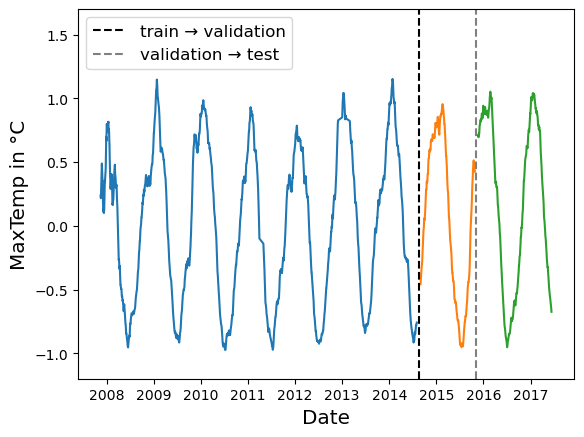

In [8]:
val_start = X_val["Date"].min()
test_start = X_test["Date"].min()


yearly = X_train.groupby("Date")["MaxTemp"].mean().rolling(30, center=True).mean()

plt.plot(yearly)
plt.ylabel('MaxTemp in °C', size="x-large")
plt.xlabel("Date", size="x-large")

yearly_2 = X_val.groupby("Date")["MaxTemp"].mean().rolling(30, center=True).mean()

plt.plot(yearly_2)
plt.ylabel('MaxTemp in °C', size="x-large")
plt.xlabel("Date", size="x-large")

yearly_3 = X_test.groupby("Date")["MaxTemp"].mean().rolling(30, center=True).mean()

plt.plot(yearly_3)
plt.ylabel('MaxTemp in °C', size="x-large")
plt.xlabel("Date", size="x-large")

plt.axvline(val_start, color="black", linestyle="--", label="train → validation")
plt.axvline(test_start, color="grey", linestyle="--", label="validation → test")

plt.ylim((-1.2,1.7))
plt.legend(loc="upper left", fontsize=12);

In [7]:
X_train = X_train.drop(columns=['Date'], axis=1)
X_val = X_val.drop(columns=['Date'], axis=1)
X_test = X_test.drop(columns=['Date'], axis=1)

In [8]:
cat_cols = X_train.select_dtypes(include=["object"]).columns



enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

train_base_enc = enc.fit_transform(X_train[cat_cols])
val_base_enc = enc.transform(X_val[cat_cols])
test_base_enc= enc.transform(X_test[cat_cols])


train_base_cat_df = pd.DataFrame(train_base_enc, columns=enc.get_feature_names_out(cat_cols), index=X_train.index)
val_base_cat_df = pd.DataFrame(val_base_enc, columns=enc.get_feature_names_out(cat_cols), index=X_val.index)
test_base_cat_df = pd.DataFrame(test_base_enc, columns=enc.get_feature_names_out(cat_cols), index=X_test.index)


X_train = pd.concat([X_train.drop(columns=cat_cols), train_base_cat_df], axis=1)
X_val = pd.concat([X_val.drop(columns=cat_cols), val_base_cat_df], axis=1)
X_test = pd.concat([X_test.drop(columns=cat_cols), test_base_cat_df], axis=1)

In [9]:
y_train_num= y_train.replace({"Yes": 1, "No": 0})
y_test_num= y_test.replace({"Yes": 1, "No": 0})
y_val_num= y_val.replace({"Yes": 1, "No": 0})

**Lazy Classifier**

In [78]:
from lazypredict import LazyClassifier

clf = LazyClassifier(verbose=0,ignore_warnings=True, custom_metric=None)
models,predictions = clf.fit(X_train, X_val, y_train_num, y_val_num)

models.sort_values("ROC AUC", ascending=False)


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
LGBMClassifier,0.859410,0.721678,0.878693,0.847775,0.849871,0.859410,0.944627
XGBClassifier,0.858088,0.724346,0.875445,0.847421,0.848238,0.858088,0.880541
ExtraTreesClassifier,0.855787,0.700751,0.871637,0.839944,0.846560,0.855787,15.452690
RandomForestClassifier,0.854522,0.703765,0.870173,0.839861,0.844337,0.854522,15.701244
SVC,0.860100,0.706456,0.860176,0.844500,0.852432,0.860100,320.412051
LinearSVC,0.848082,0.692291,0.853063,0.832318,0.836121,0.848082,0.685708
CalibratedClassifierCV,0.848082,0.697235,0.853059,0.833660,0.835947,0.848082,2.332590
LogisticRegression,0.848830,0.700075,0.853033,0.834925,0.836870,0.848830,0.349333
RidgeClassifierCV,0.846300,0.682618,0.850846,0.828346,0.834321,0.846300,0.488803


In [79]:
fitted = clf.models   # Dict: Modellname -> gefittete Pipeline

ap = {}
for name, pipe in fitted.items():
    try:
        if hasattr(pipe, "predict_proba"):
            score = pipe.predict_proba(X_val)[:, 1]
        elif hasattr(pipe, "decision_function"):
            score = pipe.decision_function(X_val)
        else:
            continue          # Modell liefert keine Scores
        ap[name] = average_precision_score(y_val_num, score)
    except Exception:
        continue              # einzelne Modelle können scheitern

models["AP"] = pd.Series(ap)
models.sort_values("AP", ascending=False)

C:\Users\Irmigeheuer\AppData\Roaming\Python\Python39\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken,AP
Model,,,,,,,,
LGBMClassifier,0.859410,0.721678,0.878693,0.847775,0.849871,0.859410,0.944627,0.705197
XGBClassifier,0.858088,0.724346,0.875445,0.847421,0.848238,0.858088,0.880541,0.703050
SVC,0.860100,0.706456,0.860176,0.844500,0.852432,0.860100,320.412051,0.700405
ExtraTreesClassifier,0.855787,0.700751,0.871637,0.839944,0.846560,0.855787,15.452690,0.685087
RandomForestClassifier,0.854522,0.703765,0.870173,0.839861,0.844337,0.854522,15.701244,0.681471
LogisticRegression,0.848830,0.700075,0.853033,0.834925,0.836870,0.848830,0.349333,0.647055
CalibratedClassifierCV,0.848082,0.697235,0.853059,0.833660,0.835947,0.848082,2.332590,0.644066
LinearSVC,0.848082,0.692291,0.853063,0.832318,0.836121,0.848082,0.685708,0.644014
RidgeClassifier,0.846300,0.682618,0.850845,0.828346,0.834321,0.846300,0.231787,0.638287


**LightGBM Training - Baseline**

In [12]:
def score(probabilite, seuil):
    return (probabilite >= seuil).astype(int)


thresholds = np.arange(0, 1, 0.001)


model=LGBMClassifier(
            objective='binary',
            boosting_type='gbdt',
            random_state=42,
            feature_fraction_seed=42,
            bagging_seed=42,
            data_random_seed=42,
            deterministic=True,
            force_col_wise=True,
            verbosity=-1,
            n_jobs=1
        )


results_train=[]
results_val = []
results_test = []


model.fit(X_train, y_train_num)

############ Predictions and train ########################

prob_train = model.predict_proba(X_train)[:, 1]

#validation
aps = average_precision_score(y_train_num, prob_train)
roc = roc_auc_score(y_train_num, prob_train)

#Store validation results
results_train.append({
        'Train-AP': aps,
        'Train-ROC-AUC': roc,
})


############ Predictions and validation ########################

prob_val = model.predict_proba(X_val)[:, 1]

#validation
aps = average_precision_score(y_val_num, prob_val)
roc = roc_auc_score(y_val_num, prob_val)

    # Optimize threshold using validation data
scores = [
    f1_score(y_val_num, score(prob_val, t), zero_division=0)
    for t in thresholds
]

ix = np.argmax(scores)

final_thres = thresholds[ix]
f1 = scores[ix]

print("Optimal threshold: ", final_thres)

#Store validation results
results_val.append({
        'Val-AP': aps,
        'Val-ROC-AUC': roc,
        'Val-F1': f1,
        'Threshold': final_thres
})


############ Predictions and test ########################

prob_test = model.predict_proba(X_test)[:, 1]

# Apply validation threshold
preds_f1 = score(prob_test, final_thres)

# Metrics
aps = average_precision_score(y_test_num, prob_test)
roc = roc_auc_score(y_test_num, prob_test)
f1_score_test = f1_score(
    y_test_num,
    preds_f1,
    zero_division=0
)

# Store test results
results_test.append({
    'Test-AP': aps,
    'Test-ROC-AUC': roc,
    'Test-F1': f1_score_test,
    'Threshold': final_thres
})


# Display results as DataFrames

results_val_df = (
    pd.DataFrame(results_val)
    .sort_values(by='Val-AP', ascending=False)
)

results_test_df = (
    pd.DataFrame(results_test)
    .sort_values(by='Test-AP', ascending=False)
)

results_train_df = (
    pd.DataFrame(results_train)
    .sort_values(by='Train-AP', ascending=False)
)

print("\nTrain_results")
print(results_train_df)

print("\nVal_results")
print(results_val_df)

print("\nTest_results")
print(results_test_df)


Optimal threshold:  0.274

Train_results
   Train-AP  Train-ROC-AUC
0  0.784555       0.906266

Val_results
     Val-AP  Val-ROC-AUC    Val-F1  Threshold
0  0.706179     0.878967  0.637737      0.274

Test_results
   Test-AP  Test-ROC-AUC   Test-F1  Threshold
0  0.71741      0.873311  0.642594      0.274


**LightGBM Training - Hyperparameter Tuning**

In [25]:
def score(probabilite, seuil):
    return (probabilite >= seuil).astype(int)


thresholds = np.arange(0, 1, 0.001)


# Model and Parameters
param_grids = {
    "LightGBM": {
        'model': LGBMClassifier(
            objective='binary',
            boosting_type='gbdt',
            random_state=42,
            feature_fraction_seed=42,
            bagging_seed=42,
            data_random_seed=42,
            deterministic=True,
            force_col_wise=True,
            verbosity=-1,
            n_jobs=1
        ),
        'params': {
            'n_estimators': [100, 100, 500],
            'learning_rate': [0.03, 0.05, 0.1],
            'num_leaves': [15, 31, 50],
            'max_depth': [None, 10, 20]
        }
    }
}


# Training and evaluation of the model

results_val = []
results_test = []

for name, cfg in param_grids.items():

    print(f"\nTraining model {name}...")

    cv = TimeSeriesSplit(n_splits=3)

    grid = GridSearchCV(
        cfg['model'],
        cfg['params'],
        cv=cv,
        scoring='average_precision',
        n_jobs=-1
    )

    grid.fit(X_train, y_train_num)

    print(f"Best parameters for {name}: {grid.best_params_}")
    print(f"Mean CV AP score: {grid.best_score_:.4f}")

    best = grid.best_index_

    fold_scores = [
        grid.cv_results_[f"split{i}_test_score"][best]
        for i in range(cv.get_n_splits())
    ]

    print("AP Score per Fold:", [round(s, 4) for s in fold_scores])
    print(f"Mean {np.mean(fold_scores):.4f}  Std {np.std(fold_scores):.4f}")


    ############ Predictions and validation ########################

    prob_val = grid.predict_proba(X_val)[:, 1]

    # AP and ROC-AUC
    aps = average_precision_score(y_val_num, prob_val)
    roc = roc_auc_score(y_val_num, prob_val)

    # Optimize threshold using validation data
    scores = [
        f1_score(y_val_num, score(prob_val, t), zero_division=0)
        for t in thresholds
    ]

    ix = np.argmax(scores)

    final_thres = thresholds[ix]
    f1 = scores[ix]

    print("Optimal threshold: ", final_thres)

    # Store validation results
    results_val.append({
        'Model': name,
        'CV-AP': grid.best_score_,
        'Val-AP': aps,
        'Val-ROC-AUC': roc,
        'Val-F1': f1,
        'Threshold': final_thres
    })


    ############ Predictions and test ########################

    prob_test = grid.predict_proba(X_test)[:, 1]

    # Apply validation threshold
    preds_f1 = score(prob_test, final_thres)

    # Metrics
    aps = average_precision_score(y_test_num, prob_test)
    roc = roc_auc_score(y_test_num, prob_test)
    f1_score_test = f1_score(
        y_test_num,
        preds_f1,
        zero_division=0
    )

    # Store test results
    results_test.append({
        'Model': name,
        'CV-AP': grid.best_score_,
        'Test-AP': aps,
        'Test-ROC-AUC': roc,
        'Test-F1': f1_score_test,
        'Threshold': final_thres
    })


# Display results as DataFrames

results_val_df = (
    pd.DataFrame(results_val)
    .sort_values(by='Val-AP', ascending=False)
)

results_test_df = (
    pd.DataFrame(results_test)
    .sort_values(by='Test-AP', ascending=False)
)

print("\nVal_results")
print(results_val_df)

print("\nTest_results")
print(results_test_df)



Training model LightGBM...
Best parameters for LightGBM: {'learning_rate': 0.03, 'max_depth': None, 'n_estimators': 500, 'num_leaves': 31}
Mean CV AP score: 0.7367
AP Score per Fold: [0.7493, 0.7117, 0.7491]
Mean 0.7367  Std 0.0177
Optimal threshold:  0.28500000000000003

Val_results
      Model     CV-AP    Val-AP  Val-ROC-AUC    Val-F1  Threshold
0  LightGBM  0.736714  0.709594     0.880926  0.641727      0.285

Test_results
      Model     CV-AP   Test-AP  Test-ROC-AUC   Test-F1  Threshold
0  LightGBM  0.736714  0.718647      0.875347  0.647563      0.285


**LightGBM Training Tuned**

In [30]:
def score(probabilite, seuil):
    return (probabilite >= seuil).astype(int)


thresholds = np.arange(0, 1, 0.001)


model=LGBMClassifier(
            objective='binary',
            boosting_type='gbdt',
            random_state=42,
            feature_fraction_seed=42,
            bagging_seed=42,
            data_random_seed=42,
            deterministic=True,
            force_col_wise=True,
            verbosity=-1,
            learning_rate=0.03,
            max_depth=None,
            n_estimators=500,
            num_leaves=31,
            n_jobs=1
        )


results_train=[]
results_val = []
results_test = []


model.fit(X_train, y_train_num)

############ Predictions and train ########################

prob_train = model.predict_proba(X_train)[:, 1]

#validation
aps = average_precision_score(y_train_num, prob_train)
roc = roc_auc_score(y_train_num, prob_train)

#Store validation results
results_train.append({
        'Train-AP': aps,
        'Train-ROC-AUC': roc,
})


############ Predictions and validation ########################

prob_val = model.predict_proba(X_val)[:, 1]

#validation
aps = average_precision_score(y_val_num, prob_val)
roc = roc_auc_score(y_val_num, prob_val)

    # Optimize threshold using validation data
scores = [
    f1_score(y_val_num, score(prob_val, t), zero_division=0)
    for t in thresholds
]

ix = np.argmax(scores)

final_thres = thresholds[ix]
f1 = scores[ix]

print("Optimal threshold: ", final_thres)

#Store validation results
results_val.append({
        'Val-AP': aps,
        'Val-ROC-AUC': roc,
        'Val-F1': f1,
        'Threshold': final_thres
})


############ Predictions and test ########################

prob_test = model.predict_proba(X_test)[:, 1]

# Apply validation threshold
preds_f1 = score(prob_test, final_thres)

# Metrics
aps = average_precision_score(y_test_num, prob_test)
roc = roc_auc_score(y_test_num, prob_test)
f1_score_test = f1_score(
    y_test_num,
    preds_f1,
    zero_division=0
)

# Store test results
results_test.append({
    'Test-AP': aps,
    'Test-ROC-AUC': roc,
    'Test-F1': f1_score_test,
    'Threshold': final_thres
})


# Display results as DataFrames

results_val_df = (
    pd.DataFrame(results_val)
    .sort_values(by='Val-AP', ascending=False)
)

results_test_df = (
    pd.DataFrame(results_test)
    .sort_values(by='Test-AP', ascending=False)
)

results_train_df = (
    pd.DataFrame(results_train)
    .sort_values(by='Train-AP', ascending=False)
)

print("\nTrain_results")
print(results_train_df)

print("\nVal_results")
print(results_val_df)

print("\nTest_results")
print(results_test_df)


Optimal threshold:  0.28500000000000003

Train_results
   Train-AP  Train-ROC-AUC
0  0.803408       0.915985

Val_results
     Val-AP  Val-ROC-AUC    Val-F1  Threshold
0  0.709594     0.880926  0.641727      0.285

Test_results
    Test-AP  Test-ROC-AUC   Test-F1  Threshold
0  0.718647      0.875347  0.647563      0.285


In [16]:
import shap
from IPython.display import display
pd.set_option('display.max_columns', None)

explainer = shap.TreeExplainer(model,
    data=X_train,
    feature_perturbation="interventional",
    model_output="probability")

shap_values = explainer.shap_values(X_test)


 99%|===================| 22978/23188 [01:34<00:00]        

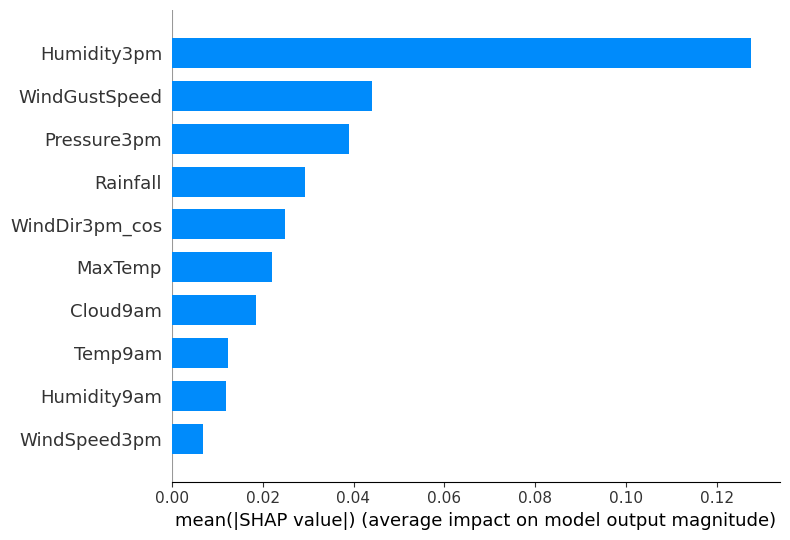

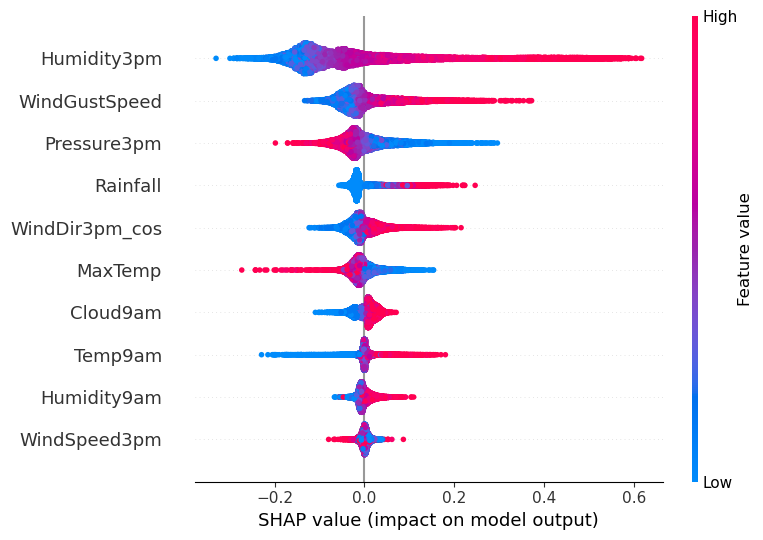

In [24]:
sv = shap_values

shap.summary_plot(sv, X_test, plot_type="bar", max_display=10)
shap.summary_plot(sv, X_test, max_display=10)


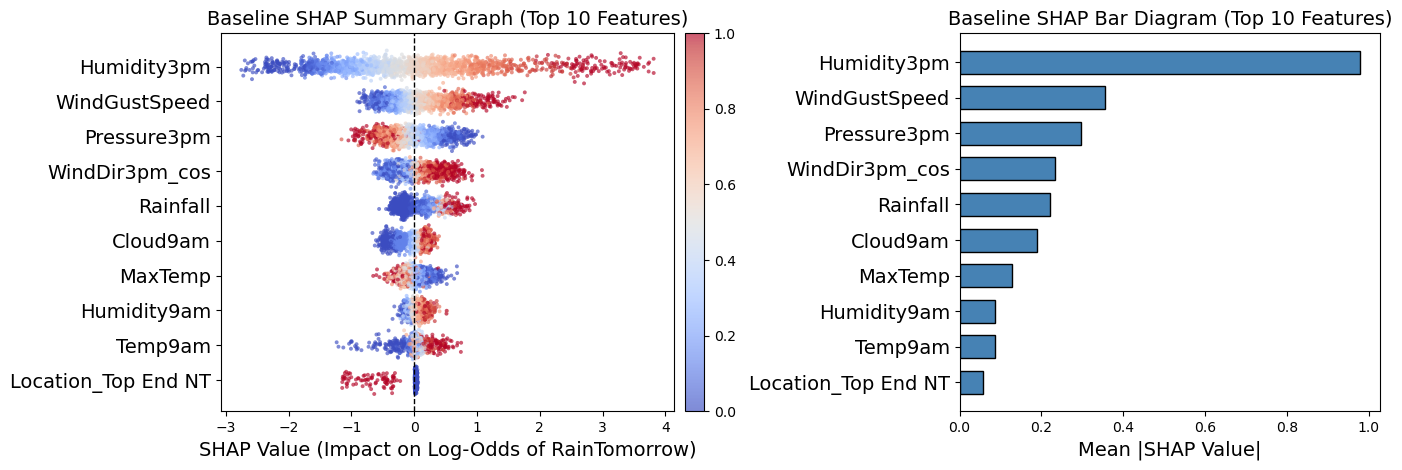

,Feature,Mean |SHAP Value|
0,Humidity3pm,0.9786
1,WindGustSpeed,0.3556
2,Pressure3pm,0.2963
3,WindDir3pm_cos,0.2332
4,Rainfall,0.2217
5,Cloud9am,0.1883
6,MaxTemp,0.1277
7,Humidity9am,0.0870
8,Temp9am,0.0853
9,Location_Top End NT,0.0565


In [39]:
base_cols = list(X_train.columns)

shap_matrix_base = model.predict(X_val, pred_contrib=True)[:, :-1]
shap_base = pd.Series(
    np.abs(shap_matrix_base).mean(axis=0),
    index=base_cols
).sort_values(ascending=False)

# Plot Top 10 Baseline SHAP Summary Graph (left) and Bar Diagram (right)
top10_cols = shap_base.head(10).index[::-1].tolist()
top10_idx  = [base_cols.index(c) for c in top10_cols]

rng = np.random.default_rng(42)
sample_rows = rng.choice(len(X_val), size=2000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.3, 1.0]})

for pos, col_idx in enumerate(top10_idx):
    sv = shap_matrix_base[sample_rows, col_idx]
    fv = X_val.iloc[sample_rows, col_idx].values
    fv_norm = np.clip((fv - np.percentile(fv, 5)) / (np.percentile(fv, 95) - np.percentile(fv, 5) + 1e-9), 0, 1)
    y_jitter = pos + rng.normal(0, 0.13, size=len(sv))
    sc = axes[0].scatter(sv, y_jitter, c=fv_norm, cmap='coolwarm', s=8, alpha=0.65, edgecolors='none')

axes[0].axvline(0, color='black', linestyle='--', lw=1)
axes[0].set_yticks(range(len(top10_cols)))
axes[0].set_yticklabels(top10_cols, fontsize=14)
axes[0].set_xlabel('SHAP Value (Impact on Log-Odds of RainTomorrow)',fontsize=14)
axes[0].set_title('Baseline SHAP Summary Graph (Top 10 Features)', fontsize=14)
plt.colorbar(sc, ax=axes[0], pad=0.02)

axes[1].barh(top10_cols, [shap_base[c] for c in top10_cols], color='steelblue', edgecolor='black', height=0.65)
axes[1].tick_params(axis='y', labelsize=14)
axes[1].set_xlabel('Mean |SHAP Value|', fontsize=14)
axes[1].set_title('Baseline SHAP Bar Diagram (Top 10 Features)', fontsize=14)

plt.tight_layout()
plt.show()

# Display Top 10 SHAP Values
shap_summary = pd.DataFrame({
    'Feature': shap_base.head(10).index,
    'Mean |SHAP Value|': shap_base.head(10).values
})

display(shap_summary.round(4))

**Grid Search Classical Models**

In [21]:
def score(probabilite, seuil):
    return (probabilite >= seuil).astype('int')


thresholds = np.arange(0, 1, 0.001)

#dictionary:
param_grids = {
    "ExtraTreeClassifier": {
        'model': ExtraTreesClassifier(random_state=42),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [None, 10, 20],
            'min_samples_split': [2, 5],
            "criterion":['gini',"entropy"]
        }  
    },
    "Random Forest": {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators': [100, 200,500],
            'max_depth': [None, 10, 20],
            'min_samples_split': [2, 5],
            "criterion":['gini',"entropy"]
        }
    },
    "SVC": {
        'model': SVC(probability=True, random_state=42),
        'params': {
            'C': [0.1, 1],
            "kernel":["poly", "rbf"],
            "gamma":[0.01, 0.1]
        }
    }
}

#Training and evaluation of the model:

results_val = []
results_test = []

for name, cfg in param_grids.items():
    print(f"\nTraining model {name}...")
    
    cv = TimeSeriesSplit(n_splits=3)
    
    grid = GridSearchCV(cfg['model'], cfg['params'], cv=cv, scoring='average_precision') #n_jobs=1
    grid.fit(X_train, y_train_num)

    print(f"Best parameters for {name}: {grid.best_params_ if grid.best_params_ else '---'}")
    print(f"Mean CV AP score: {grid.best_score_:.4f}")
    best = grid.best_index_
    fold_scores = [grid.cv_results_[f"split{i}_test_score"][best] for i in range(cv.get_n_splits())]
    print("AP pro Fold:", [round(s, 4) for s in fold_scores])
    print(f"Mittel {np.mean(fold_scores):.4f}  Std {np.std(fold_scores):.4f}")

 ############ Predictions and validation  ########################
    y_pred_val = grid.predict(X_val)
    prob_val=grid.predict_proba(X_val)[:, 1]  

# AP and ROC-AUC
    aps = average_precision_score(y_val_num, prob_val)
    roc = roc_auc_score(y_val_num, prob_val)
  
# Optimize threshold using validation data    
    scores = [f1_score(y_val_num, score(prob_val, t)) for t in thresholds]
    ix = np.argmax(scores)
    final_thres = thresholds[ix]
    f1=scores[ix]

    # Store in results list
    results_val.append({
        'Model': name,
        'CV-AP': grid.best_score_, 
        'Val-AP': aps,
        'Val-ROC-AUC': roc,
        'Val-F1': f1,
        'Threshold': final_thres
    })

  ############ Predictions and test  ######################## 

    preds_f1 = np.where(grid.predict_proba(X_test)[:, 1] > final_thres, 1, 0)
    prob_test = grid.predict_proba(X_test)[:, 1]

    # Metrics
    aps = average_precision_score(y_test_num, prob_test)
    roc = roc_auc_score(y_test_num, prob_test)
    f1_score_test = f1_score(y_test_num, preds_f1)

    results_test.append({
        'Model': name,
        'CV-AP': grid.best_score_,
        'Test-AP': aps,
        'Test-ROC-AUC': roc,
        'Test-F1': f1_score_test,
        'Threshold': final_thres
    })


# Display results as a DataFrame
results_val_df = pd.DataFrame(results_val).sort_values(by='Val-AP', ascending=False)
results_test_df = pd.DataFrame(results_test).sort_values(by='Test-AP', ascending=False)
print("Val_results")
print(results_val_df)
print("\n")
print("Test_results")
print(results_test_df)



Training model ExtraTreeClassifier...
Best parameters for ExtraTreeClassifier: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
Mean CV AP score: 0.7298
AP pro Fold: [0.7382, 0.7078, 0.7434]
Mittel 0.7298  Std 0.0157

Training model Random Forest...
Best parameters for Random Forest: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 5, 'n_estimators': 500}
Mean CV AP score: 0.7305
AP pro Fold: [0.7392, 0.7075, 0.7447]
Mittel 0.7305  Std 0.0164

Training model SVC...
Best parameters for SVC: {'C': 1, 'gamma': 0.1, 'kernel': 'poly'}
Mean CV AP score: 0.7271
AP pro Fold: [0.7415, 0.6971, 0.7427]
Mittel 0.7271  Std 0.0212
Val_results
                 Model     CV-AP    Val-AP  Val-ROC-AUC    Val-F1  Threshold
2                  SVC  0.727094  0.700194     0.860691  0.643418      0.214
0  ExtraTreeClassifier  0.729799  0.697310     0.876228  0.630500      0.333
1        Random Forest  0.730460  0.696406     0.876693  0.631018      0.33

**resampling**

In [31]:
d={
    "NoSampler": None,
    "RandomOverSampler": RandomOverSampler(sampling_strategy='not majority'),
    "SMOTE": SMOTE(),
    "RandomUnderSampler": RandomUnderSampler(sampling_strategy='majority'),
    "ClusterCentroids": ClusterCentroids(),
}

def score(probabilite, seuil):
    return (probabilite >= seuil).astype('int')

thresholds = np.arange(0, 1, 0.001)


results_train = []
results_val = []
results_test = []

for name, sampler in d.items():

    print(name)

    if sampler is None:
        X_train_res, y_train_res=X_train, y_train_num
    else:
        X_train_res, y_train_res=sampler.fit_resample(X_train, y_train_num)


    model = ExtraTreesClassifier(criterion= 'entropy', max_depth= None, min_samples_split= 5, n_estimators= 500, n_jobs= -1, random_state= 42)

    model.fit(X_train_res, y_train_res)


    ######training set#############################
    y_probs_train = model.predict_proba(X_train)[:, 1]
    
    results_train.append({
        'Model': name,
        'Train-AP': average_precision_score(y_train_num, y_probs_train),
        'Train-ROC-AUC': roc_auc_score(y_train_num, y_probs_train),
    })

    
    ######finding threshold on validation set#############################
    y_probs = model.predict_proba(X_val)[:, 1]

    scores = [f1_score(y_val_num, score(y_probs, t)) for t in thresholds]

    ix = np.argmax(scores)

    final_thres = thresholds[ix]

    results_val.append({
        'Model': name,
        'Threshold': final_thres,
        'Val-AP': average_precision_score(y_val_num, y_probs),
        'Val-ROC-AUC': roc_auc_score(y_val_num, y_probs),
        'Val-F1': scores[ix],
    })


    ######applying threshold to test set#############################
    y_probs_test = model.predict_proba(X_test)[:, 1]

    preds = np.where(model.predict_proba(X_test)[:, 1] > final_thres, 1, 0)
      
    results_test.append({
        'Model': name,
        'Threshold': final_thres,
        'Test-AP': average_precision_score(y_test_num, y_probs_test),
        'Test-ROC-AUC': roc_auc_score(y_test_num, y_probs_test),
        'Test-F1': f1_score(y_test_num, preds),
    })


# Display results as a DataFrame
results_train_df = pd.DataFrame(results_train).sort_values(by='Train-AP', ascending=False)
results_val_df = pd.DataFrame(results_val).sort_values(by='Val-AP', ascending=False)
results_test_df = pd.DataFrame(results_test).sort_values(by='Test-AP', ascending=False)
print("\n")
print("Train_results")
print(results_train_df)
print("\n")
print("Val_results")
print(results_val_df)
print("\n")
print("Test_results")
print(results_test_df)


NoSampler
RandomOverSampler


C:\Users\Irmigeheuer\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
C:\Users\Irmigeheuer\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


SMOTE


C:\Users\Irmigeheuer\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


RandomUnderSampler


C:\Users\Irmigeheuer\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
C:\Users\Irmigeheuer\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


ClusterCentroids


C:\Users\Irmigeheuer\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(




Train_results
                Model  Train-AP  Train-ROC-AUC
1   RandomOverSampler  1.000000       1.000000
2               SMOTE  1.000000       1.000000
0           NoSampler  0.999995       0.999999
3  RandomUnderSampler  0.956589       0.988236
4    ClusterCentroids  0.900578       0.970935


Val_results
                Model  Threshold    Val-AP  Val-ROC-AUC    Val-F1
0           NoSampler      0.328  0.698159     0.876955  0.632592
1   RandomOverSampler      0.377  0.696241     0.875935  0.630279
2               SMOTE      0.410  0.695798     0.877730  0.631248
3  RandomUnderSampler      0.579  0.689936     0.874476  0.627290
4    ClusterCentroids      0.700  0.550392     0.809281  0.535633


Test_results
                Model  Threshold   Test-AP  Test-ROC-AUC   Test-F1
0           NoSampler      0.328  0.708859      0.871927  0.641989
1   RandomOverSampler      0.377  0.706766      0.870389  0.637190
2               SMOTE      0.410  0.704707      0.870866  0.634146
3  Random

**check for class_weight**

In [33]:
def score(probabilite, seuil):
    return (probabilite >= seuil).astype('int')

thresholds = np.arange(0, 1, 0.001)

results_train = []
results_val = []
results_test = []

classes=[None, "balanced", "balanced_subsample"]

for n in classes:
    model = ExtraTreesClassifier(criterion= 'entropy', max_depth= None, min_samples_split= 5, n_estimators= 500, class_weight=n, random_state= 42)
    model.fit(X_train,y_train_num)

######training set#############################
    y_probs_train = model.predict_proba(X_train)[:, 1]
    
    results_train.append({
        'class-weight': n,
        'Train-AP': average_precision_score(y_train_num, y_probs_train),
        'Train-ROC-AUC': roc_auc_score(y_train_num, y_probs_train),
    })
    
######finding threshold on validation set#############################
    
    y_pred_val = model.predict_proba(X_val)[:, 1] 

    scores = [f1_score(y_val_num, score(y_pred_val, t)) for t in thresholds]

    ix = np.argmax(scores)

    final_thres = thresholds[ix]
    
    aps = average_precision_score(y_val_num, y_pred_val)
    roc = roc_auc_score(y_val_num, y_pred_val)
    
    results_val.append({
        'class-weight': n,
        'Threshold': final_thres,
        'Val-AP': aps,
        'Val-ROC-AUC': roc,
        'Val-F1': scores[ix]
    })

     
######applying threshold to test set#############################
    preds = np.where(model.predict_proba(X_test)[:, 1] > final_thres, 1, 0)
    y_pred_test = model.predict_proba(X_test)[:, 1]

    aps_test = average_precision_score(y_test_num, y_pred_test)
    roc_test = roc_auc_score(y_test_num, y_pred_test)
    
    results_test.append({
        'class-weight': n,
        'Threshold': final_thres,
        'Test-AP': aps_test,
        'Test-ROC-AUC': roc_test,
        'Test-F1': f1_score(y_test_num, preds),
    })


# Display results as a DataFrame
results_train_df = pd.DataFrame(results_train).sort_values(by='Train-AP', ascending=False)
results_val_df = pd.DataFrame(results_val).sort_values(by='Val-AP', ascending=False)
results_test_df = pd.DataFrame(results_test).sort_values(by='Test-AP', ascending=False)
print("\n")
print("Train_results")
print(results_train_df)
print("\n")
print("Val_results")
print(results_val_df)
print("\n")
print("Test_results")
print(results_test_df)




Train_results
         class-weight  Train-AP  Train-ROC-AUC
1            balanced  1.000000       1.000000
2  balanced_subsample  1.000000       1.000000
0                None  0.999995       0.999999


Val_results
         class-weight  Threshold    Val-AP  Val-ROC-AUC    Val-F1
0                None      0.328  0.698158     0.876955  0.632592
1            balanced      0.423  0.696638     0.876531  0.632773
2  balanced_subsample      0.423  0.696638     0.876531  0.632773


Test_results
         class-weight  Threshold   Test-AP  Test-ROC-AUC   Test-F1
0                None      0.328  0.708858      0.871926  0.641989
1            balanced      0.423  0.707908      0.871434  0.640211
2  balanced_subsample      0.423  0.707908      0.871434  0.640211


**Neuronal Network**

In [11]:
X_train.shape[1]

30

In [10]:

################### APS calculation #####################################
class APSCallback(tf.keras.callbacks.Callback):
    def __init__(self, X_train, y_train, X_val, y_val):
        super().__init__()
        self.X_train = X_train
        self.y_train = y_train
        self.X_val = X_val
        self.y_val = y_val

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}

        # Train AP
        proba_train = self.model.predict(self.X_train, verbose=0).ravel()
        aps_train = average_precision_score(self.y_train, proba_train)

        # Validation AP
        proba_val = self.model.predict(self.X_val, verbose=0).ravel()
        aps_val = average_precision_score(self.y_val, proba_val)

        logs["train_aps"] = aps_train
        logs["val_aps"] = aps_val

        print(f" - train_aps: {aps_train:.4f} - val_aps: {aps_val:.4f}")

aps_cb = APSCallback(
    X_train, y_train_num,
    X_val, y_val_num
)


######### Neural Network ###############################
inputs = Input(shape=(X_train.shape[1],))

x = layers.Dense(64, activation='relu')(inputs)
x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)

outputs = layers.Dense(1, activation='sigmoid')(x)

model = Model(inputs=inputs, outputs=outputs)


model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_aps", mode="max", patience=15, restore_best_weights=True
)

history = model.fit(
    X_train, y_train_num,
    validation_data=(X_val, y_val_num),
    batch_size=32,
    epochs=35,
    callbacks=[aps_cb, early_stop],
    verbose=1
)



Epoch 1/35
2352/2356 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7900 - auc: 0.7213 - loss: 0.4762 - precision: 0.5420 - recall: 0.1435 - train_aps: 0.6786 - val_aps: 0.6294
2356/2356 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.7900 - auc: 0.7215 - loss: 0.4761 - precision: 0.5423 - recall: 0.1439 - val_accuracy: 0.8447 - val_auc: 0.8536 - val_loss: 0.3610 - val_precision: 0.6598 - val_recall: 0.5111 - train_aps: 0.6786 - val_aps: 0.6294
Epoch 2/35
2349/2356 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8359 - auc: 0.8506 - loss: 0.3811 - precision: 0.6896 - recall: 0.5185 - train_aps: 0.7023 - val_aps: 0.6602
2356/2356 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.8359 - auc: 0.8507 - loss: 0.3811 - precision: 0.6896 - recall: 0.5185 - val_accuracy: 0.8502 - val_auc: 0.8628 - val_loss: 0.3493 - val_precision: 0.6970 - val_recall: 0.4850 - train_aps: 0.7023 - val_aps: 0.6602
Epoch 3/35
2347/2356 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8440 - auc: 0.8598 - loss: 0.3665 

In [12]:
model.save("nn_w_0.h5") 

import pickle

model.save("nn_w_0.keras")
with open("nn_w_0_history.pkl", "wb") as f:
    pickle.dump(history.history, f)

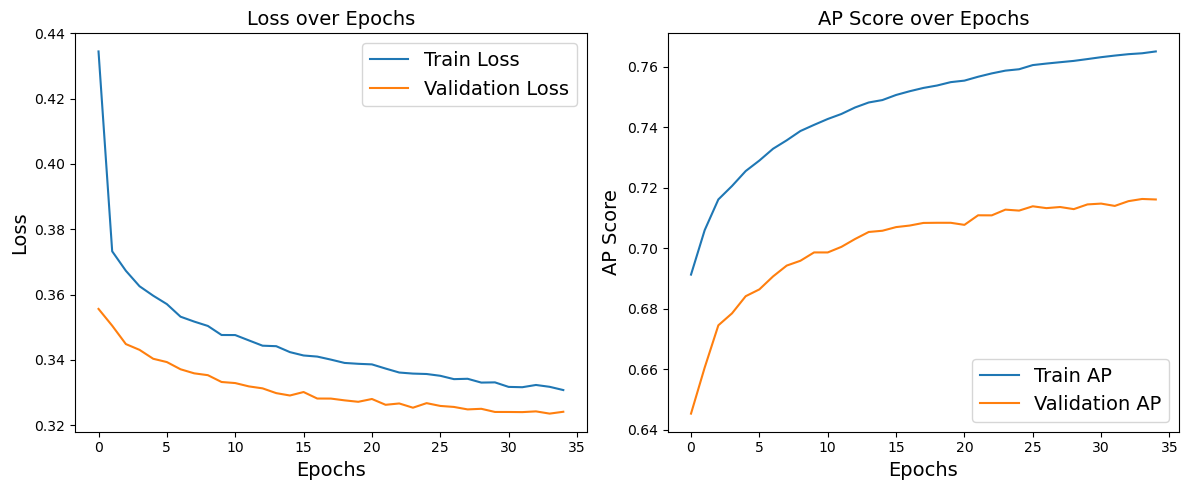

In [47]:
plt.figure(figsize=(12, 5))
# Loss plot
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs', fontsize=14)
plt.xlabel('Epochs', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.legend(fontsize=14)

plt.subplot(1, 2, 2)
plt.plot(history.history['train_aps'],label='Train AP')
plt.plot(history.history['val_aps'],label='Validation AP')
plt.title('AP Score over Epochs', fontsize=14)
plt.xlabel('Epochs', fontsize=14)
plt.ylabel('AP Score', fontsize=14)
plt.legend(fontsize=14)

plt.tight_layout();

In [48]:
y_proba_train = model.predict(X_train)#.ravel()
y_proba_val = model.predict(X_val)#.ravel()

print("Train-AP:      ", average_precision_score(y_train_num, y_proba_train))
print("Val-ROC:      ", roc_auc_score(y_val_num, y_proba_val))
print("Val-AP:      ", average_precision_score(y_val_num, y_proba_val))

y_proba_test = model.predict(X_test)
print("Test-ROC-AUC:  ", roc_auc_score(y_test_num, y_proba_test))   
print("Test-AP:      ", average_precision_score(y_test_num, y_proba_test))

######finding threshold on validation set#############################
def score(probabilite, seuil):
    return (probabilite >= seuil).astype('int')

thresholds = np.arange(0, 1, 0.001)

scores = [f1_score(y_val_num, score(y_proba_val, t)) for t in thresholds]

ix = np.argmax(scores)

final_thres = thresholds[ix]
    
f1=scores[ix]

print("Threshold ValidationSet:", final_thres)
print("F1 (Validation):", scores[ix])


#########applying threshold to test set######################
preds_test = score(y_proba_test, final_thres)

print("Test-F1:", f1_score(y_test_num, preds_test))

2356/2356 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
544/544 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Train-AP:       0.7644714899614966
Val-ROC:       0.8829241916384485
Val-AP:       0.7163220798233185
725/725 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Test-ROC-AUC:   0.8785618896907584
Test-AP:       0.7224014928609119
Threshold ValidationSet: 0.292
F1 (Validation): 0.6447454951992635
Test-F1: 0.6504206053247766
